
# Software-First Digital Twin for Multi-Agent Robot Synchronization

## Advanced Control Systems Simulation

This notebook implements a **5-agent leader–follower robotic formation** entirely in software.

### Main engineering features
- Nonholonomic unicycle dynamics with actuator lag and saturation.
- RK4 numerical integration.
- Body-frame formation-error transformation.
- PID control with anti-windup and adaptive gain scheduling.
- Physics-informed dead reckoning during communication blackouts.
- Per-agent Gilbert–Elliott burst-loss wireless network with latency.
- Distributed neighbor-coupled formation control.
- Artificial-potential collision avoidance.
- Monte-Carlo robustness analysis over packet loss and sensor noise.
- Automated PID gain screening using a Routh–Hurwitz constraint.
- Quantitative comparison of ZOH, PIDR, and advanced distributed control.
- Formation geometry, control effort, network health, safety metrics, and animation.


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

np.set_printoptions(precision=3, suppress=True)
SEED=42
rng=np.random.default_rng(SEED)
DT=0.05
T_FINAL=45.0
T=np.arange(0,T_FINAL+DT,DT)
N=len(T)
N_AGENTS=5
LEADER=0
FOLLOWERS=np.arange(1,N_AGENTS)
FORMATION=np.array([[0.0,0.0],[-1.25,0.85],[-1.25,-0.85],[-2.50,1.70],[-2.50,-1.70]])
WORLD_LIMITS=(-4,22,-7,9)

@dataclass
class Config:
    kp: float=1.8
    ki: float=0.18
    kd: float=0.65
    k_neighbor: float=0.55
    k_avoid: float=0.75
    safe_distance: float=0.70
    max_v: float=1.25
    max_w: float=2.4
    tau_motor: float=0.12
    sensor_sigma: float=0.025
    packet_good_to_bad: float=0.025
    packet_bad_to_good: float=0.22
    base_delay_steps: int=1
    max_delay_steps: int=4
CFG=Config()
print(f"Agents: {N_AGENTS} | Duration: {T_FINAL:.1f} s | dt: {DT:.3f} s")
print("Formation offsets:", FORMATION)


Agents: 5 | Duration: 45.0 s | dt: 0.050 s
Formation offsets: [[ 0.    0.  ]
 [-1.25  0.85]
 [-1.25 -0.85]
 [-2.5   1.7 ]
 [-2.5  -1.7 ]]


In [2]:

def wrap_angle(a): return (a+np.pi)%(2*np.pi)-np.pi

def rk4_step(state,command,dt,tau):
    def f(s):
        x,y,th,v,w=s; vc,wc=command
        return np.array([v*np.cos(th),v*np.sin(th),w,(vc-v)/tau,(wc-w)/tau])
    k1=f(state); k2=f(state+0.5*dt*k1); k3=f(state+0.5*dt*k2); k4=f(state+dt*k3)
    return state+(dt/6)*(k1+2*k2+2*k3+k4)

def leader_command(t):
    return np.array([0.82+0.16*np.sin(0.18*t),0.28*np.sin(0.24*t)+0.16*np.sin(0.075*t+0.8)])

def body_to_world(offset,pose):
    x,y,th=pose[:3]; c,s=np.cos(th),np.sin(th)
    return np.array([x+c*offset[0]-s*offset[1],y+s*offset[0]+c*offset[1]])

def world_to_body_error(target_xy,pose):
    dx,dy=target_xy[0]-pose[0],target_xy[1]-pose[1]; c,s=np.cos(pose[2]),np.sin(pose[2])
    return np.array([c*dx+s*dy,-s*dx+c*dy])

def desired_heading_to_point(target_xy,pose): return np.arctan2(target_xy[1]-pose[1],target_xy[0]-pose[0])

def adaptive_gains(kp,ki,kd,err):
    scale=1+0.75*np.tanh(abs(err)/0.75)
    return kp*scale,ki/(0.75+0.25*scale),kd*(0.85+0.35*scale)

def avoidance_vector(i,poses):
    force=np.zeros(2)
    for j in range(N_AGENTS):
        if i==j: continue
        dv=poses[i,:2]-poses[j,:2]; d=np.linalg.norm(dv)+1e-9
        if d<CFG.safe_distance:
            strength=CFG.k_avoid*(1/d-1/CFG.safe_distance)/(d*d)
            force+=strength*(dv/d)
    return force

class PID:
    def __init__(self,kp,ki,kd,limit): self.kp,self.ki,self.kd,self.limit=kp,ki,kd,limit; self.integral=0.; self.prev=0.
    def step(self,e,dt):
        de=(e-self.prev)/dt; candidate=self.kp*e+self.ki*self.integral+self.kd*de
        out=np.clip(candidate,-self.limit,self.limit)
        if abs(candidate)<self.limit: self.integral+=e*dt
        self.prev=e
        return out


In [3]:

class GilbertElliottChannel:
    def __init__(self,p_gb=0.025,p_bg=0.22,seed=1):
        self.rng=np.random.default_rng(seed); self.bad=False; self.p_gb=p_gb; self.p_bg=p_bg
    def transmit(self,packet):
        if self.bad:
            if self.rng.random()<self.p_bg: self.bad=False
        elif self.rng.random()<self.p_gb: self.bad=True
        if self.bad: return None
        delay=int(self.rng.integers(CFG.base_delay_steps,CFG.max_delay_steps+1))
        return packet.copy(),delay

def dead_reckon(last_packet,age,use_pidr=True):
    p=last_packet.copy()
    if not use_pidr: return p
    x,y,th,v,w=p
    if abs(w)<1e-7:
        x+=v*np.cos(th)*age; y+=v*np.sin(th)*age
    else:
        x+=(v/w)*(np.sin(th+w*age)-np.sin(th)); y+=(v/w)*(-np.cos(th+w*age)+np.cos(th)); th+=w*age
    p[:3]=[x,y,wrap_angle(th)]; return p


In [4]:

def initialize_agents(local_rng):
    states=np.zeros((N_AGENTS,5))
    for i in FOLLOWERS:
        xy=body_to_world(FORMATION[i],states[0])
        states[i,:3]=[xy[0]+local_rng.normal(0,.10),xy[1]+local_rng.normal(0,.10),local_rng.normal(0,.04)]
    return states

def simulate(mode="advanced",seed=42,loss_scale=1.0,sensor_sigma=None):
    local_rng=np.random.default_rng(seed); states=initialize_agents(local_rng)
    channels=[GilbertElliottChannel(CFG.packet_good_to_bad*loss_scale,CFG.packet_bad_to_good,seed+100+i) for i in FOLLOWERS]
    H={"t":T.copy(),"states":np.zeros((N,N_AGENTS,5)),"targets":np.zeros((N,N_AGENTS,2)),"errors":np.zeros((N,N_AGENTS)),"formation_rms":np.zeros(N),"min_distance":np.full(N,np.inf),"control_effort":np.zeros((N,N_AGENTS)),"packet_drop":np.zeros((N,N_AGENTS-1),bool),"blackout_age":np.zeros((N,N_AGENTS-1)),"collision":np.zeros(N,bool)}
    last_rx=[states[0].copy() for _ in FOLLOWERS]; rx_time=np.zeros(N_AGENTS-1)
    pv=[PID(CFG.kp,CFG.ki,CFG.kd,CFG.max_v) for _ in FOLLOWERS]; pw=[PID(CFG.kp*.9,CFG.ki*.5,CFG.kd*.8,CFG.max_w) for _ in FOLLOWERS]
    for k,t in enumerate(T):
        states[0]=rk4_step(states[0],leader_command(t),DT,CFG.tau_motor)
        for q,i in enumerate(FOLLOWERS):
            result=channels[q].transmit(states[0])
            if result is None:
                H["packet_drop"][k,q]=True
            else:
                packet,delay=result; last_rx[q]=packet; rx_time[q]=t-delay*DT
            age=max(0,t-rx_time[q]); est=dead_reckon(last_rx[q],age,mode!="zoh")
            target=body_to_world(FORMATION[i],est)
            neighbor_force=np.zeros(2)
            if mode=="advanced":
                for j in FOLLOWERS:
                    if i!=j:
                        desired_j=body_to_world(FORMATION[j],est)
                        neighbor_force+=CFG.k_neighbor*((target-desired_j)-(states[i,:2]-states[j,:2]))
            avoid=avoidance_vector(i,states) if mode=="advanced" else np.zeros(2)
            effective_target=target+neighbor_force+0.25*avoid
            e=world_to_body_error(effective_target,states[i]); dist=np.linalg.norm(e)
            sigma=CFG.sensor_sigma if sensor_sigma is None else sensor_sigma; e+=local_rng.normal(0,sigma,2)
            kp,ki,kd=adaptive_gains(CFG.kp,CFG.ki,CFG.kd,dist) if mode=="advanced" else (CFG.kp,CFG.ki,CFG.kd)
            pv[q].kp,pv[q].ki,pv[q].kd=kp,ki,kd; pw[q].kp,pw[q].ki,pw[q].kd=kp*.9,ki*.5,kd*.8
            vcmd=np.clip(.72+pv[q].step(e[0],DT),-.25,CFG.max_v)
            he=wrap_angle(desired_heading_to_point(effective_target,states[i])-states[i,2])
            wcmd=np.clip(pw[q].step(he+.55*np.arctan2(e[1],max(abs(e[0]),.15)),DT),-CFG.max_w,CFG.max_w)
            if np.linalg.norm(states[i,:2]-states[0,:2])<.45: vcmd=min(vcmd,.10)
            states[i]=rk4_step(states[i],[vcmd,wcmd],DT,CFG.tau_motor)
            H["targets"][k,i]=effective_target; H["errors"][k,i]=dist; H["control_effort"][k,i]=abs(vcmd)+.35*abs(wcmd)
        ds=[np.linalg.norm(states[a,:2]-states[b,:2]) for a in range(N_AGENTS) for b in range(a+1,N_AGENTS)]
        H["min_distance"][k]=min(ds)
        fe=[np.linalg.norm(states[i,:2]-body_to_world(FORMATION[i],states[0])) for i in FOLLOWERS]
        H["formation_rms"][k]=np.sqrt(np.mean(np.square(fe))); H["states"][k]=states
    H["collision"]=H["min_distance"]<.38
    return H
print("5-agent simulation engine ready.")


5-agent simulation engine ready.


Selected Routh-Hurwitz stable tuning: Kp=0.500, Ki=0.180, Kd=0.150


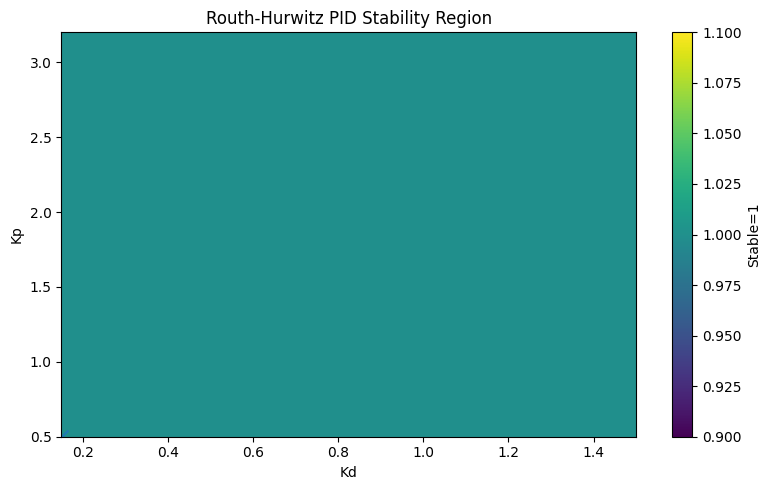

In [5]:

def routh_hurwitz_cubic(a3,a2,a1,a0):
    stable=(a3>0 and a2>0 and a1>0 and a0>0 and a2*a1>a3*a0)
    return stable,min(a3,a2,a1,a0,a2*a1-a3*a0)

def coeffs(kp,ki,kd,tau=CFG.tau_motor): return tau,1+tau*kd,kp+kd,ki
kp_grid=np.linspace(.5,3.2,16); kd_grid=np.linspace(.15,1.5,16); stable_map=np.zeros((16,16)); margin_map=np.zeros((16,16))
for a,kp in enumerate(kp_grid):
    for b,kd in enumerate(kd_grid): stable_map[a,b],margin_map[a,b]=routh_hurwitz_cubic(*coeffs(kp,CFG.ki,kd))
idx=np.unravel_index(np.argmax(np.where(stable_map>0,margin_map,-np.inf)),margin_map.shape)
best_kp,best_kd=kp_grid[idx[0]],kd_grid[idx[1]]
print(f"Selected Routh-Hurwitz stable tuning: Kp={best_kp:.3f}, Ki={CFG.ki:.3f}, Kd={best_kd:.3f}")
plt.figure(figsize=(8,5)); plt.imshow(stable_map,origin="lower",aspect="auto",extent=[kd_grid[0],kd_grid[-1],kp_grid[0],kp_grid[-1]]); plt.colorbar(label="Stable=1"); plt.scatter([best_kd],[best_kp],marker="x",s=100); plt.xlabel("Kd"); plt.ylabel("Kp"); plt.title("Routh-Hurwitz PID Stability Region"); plt.tight_layout(); plt.show()


In [6]:

hist_zoh=simulate("zoh",101); hist_pidr=simulate("pidr",101); hist_adv=simulate("advanced",101)
def metrics(h):
    t=h["t"]; e=h["formation_rms"]
    return dict(ITAE=np.trapz(t*e,t),RMSE=np.sqrt(np.mean(e**2)),Peak=np.max(e),Effort=np.mean(h["control_effort"]),MinSep=np.min(h["min_distance"]),Loss=np.mean(h["packet_drop"])*100,Collision=np.mean(h["collision"])*100)
M={n:metrics(h) for n,h in [("ZOH",hist_zoh),("PIDR",hist_pidr),("Advanced",hist_adv)]}
print("="*78); print("MULTI-AGENT DIGITAL TWIN PERFORMANCE"); print("="*78)
for n,m in M.items(): print(f"{n:9s} | ITAE={m['ITAE']:.3f} | RMSE={m['RMSE']:.3f} m | Peak={m['Peak']:.3f} m | Effort={m['Effort']:.3f} | MinSep={m['MinSep']:.3f} m | Loss={m['Loss']:.1f}% | Collision={m['Collision']:.2f}%")
print(f"PIDR improvement vs ZOH: {100*(M['ZOH']['ITAE']-M['PIDR']['ITAE'])/M['ZOH']['ITAE']:.2f}%")
print(f"Advanced improvement vs ZOH: {100*(M['ZOH']['ITAE']-M['Advanced']['ITAE'])/M['ZOH']['ITAE']:.2f}%")


MULTI-AGENT DIGITAL TWIN PERFORMANCE
ZOH       | ITAE=629.223 | RMSE=1.051 m | Peak=2.311 m | Effort=1.180 | MinSep=0.919 m | Loss=8.9% | Collision=0.00%
PIDR      | ITAE=611.387 | RMSE=1.014 m | Peak=2.230 m | Effort=1.149 | MinSep=0.285 m | Loss=8.9% | Collision=1.00%
Advanced  | ITAE=686.941 | RMSE=1.127 m | Peak=2.511 m | Effort=1.220 | MinSep=1.120 m | Loss=8.9% | Collision=0.00%
PIDR improvement vs ZOH: 2.83%
Advanced improvement vs ZOH: -9.17%


/tmp/ipykernel_912/65164843.py:4: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return dict(ITAE=np.trapz(t*e,t),RMSE=np.sqrt(np.mean(e**2)),Peak=np.max(e),Effort=np.mean(h["control_effort"]),MinSep=np.min(h["min_distance"]),Loss=np.mean(h["packet_drop"])*100,Collision=np.mean(h["collision"])*100)


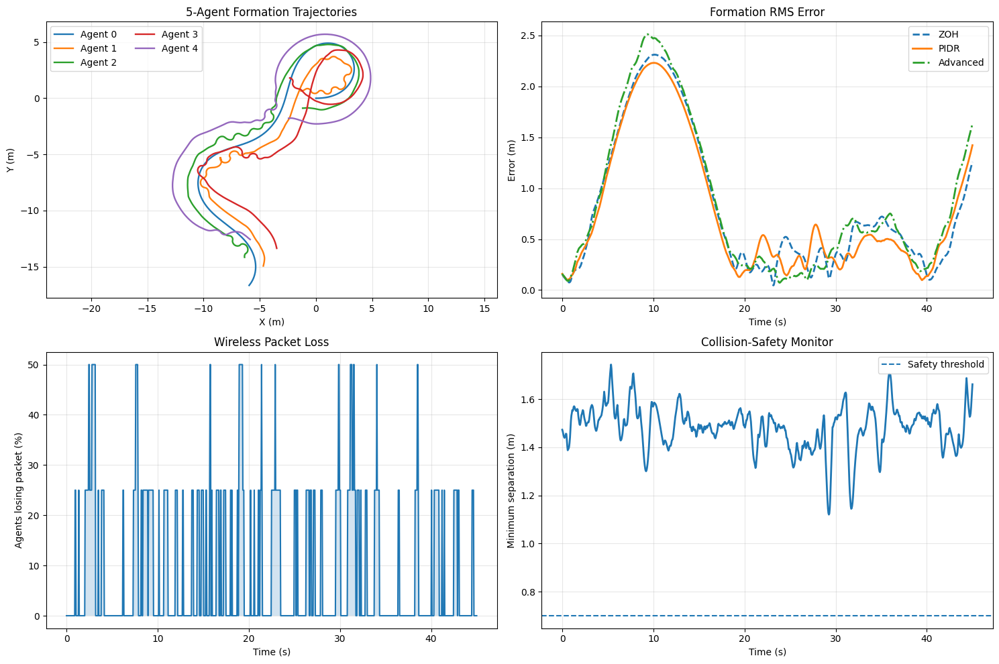

In [7]:

fig,ax=plt.subplots(2,2,figsize=(15,10))
for i in range(N_AGENTS):
    ax[0,0].plot(hist_adv["states"][:,i,0],hist_adv["states"][:,i,1],linewidth=1.7,label=f"Agent {i}")
ax[0,0].set_title("5-Agent Formation Trajectories"); ax[0,0].set_xlabel("X (m)"); ax[0,0].set_ylabel("Y (m)"); ax[0,0].axis("equal"); ax[0,0].grid(True,alpha=.3); ax[0,0].legend(ncol=2)
for n,h,style in [("ZOH",hist_zoh,"--"),("PIDR",hist_pidr,"-"),("Advanced",hist_adv,"-.")]: ax[0,1].plot(h["t"],h["formation_rms"],style,linewidth=2,label=n)
ax[0,1].set_title("Formation RMS Error"); ax[0,1].set_xlabel("Time (s)"); ax[0,1].set_ylabel("Error (m)"); ax[0,1].grid(True,alpha=.3); ax[0,1].legend()
drop=hist_adv["packet_drop"].mean(axis=1)*100; ax[1,0].plot(T,drop); ax[1,0].fill_between(T,0,drop,alpha=.2); ax[1,0].set_title("Wireless Packet Loss"); ax[1,0].set_xlabel("Time (s)"); ax[1,0].set_ylabel("Agents losing packet (%)"); ax[1,0].grid(True,alpha=.3)
ax[1,1].plot(T,hist_adv["min_distance"],linewidth=2); ax[1,1].axhline(CFG.safe_distance,linestyle="--",label="Safety threshold"); ax[1,1].set_title("Collision-Safety Monitor"); ax[1,1].set_xlabel("Time (s)"); ax[1,1].set_ylabel("Minimum separation (m)"); ax[1,1].grid(True,alpha=.3); ax[1,1].legend()
plt.tight_layout(); plt.show()


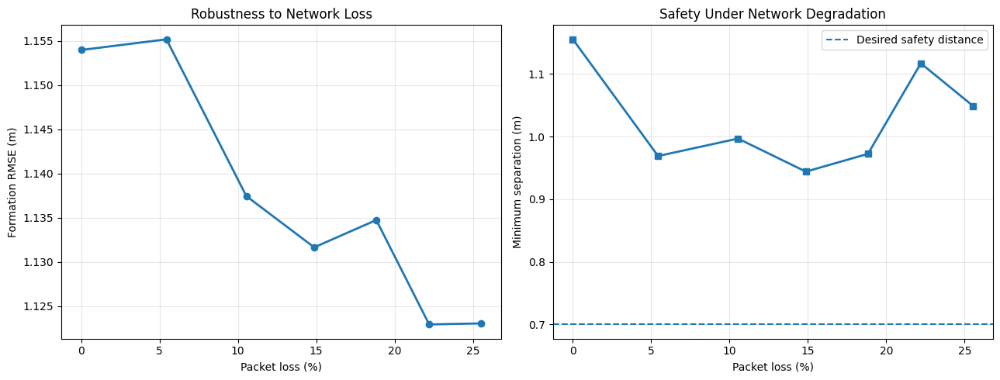

In [8]:

loss_levels=[0,.5,1,1.5,2,2.5,3]; robustness=[]
for scale in loss_levels:
    vals=[]
    for s in range(5):
        h=simulate("advanced",300+s,loss_scale=scale); vals.append([np.sqrt(np.mean(h["formation_rms"]**2)),np.max(h["formation_rms"]),np.min(h["min_distance"]),np.mean(h["packet_drop"])*100])
    robustness.append(np.mean(vals,axis=0))
robustness=np.array(robustness)
fig,ax=plt.subplots(1,2,figsize=(13,5)); ax[0].plot(robustness[:,3],robustness[:,0],"o-",linewidth=2); ax[0].set_xlabel("Packet loss (%)"); ax[0].set_ylabel("Formation RMSE (m)"); ax[0].set_title("Robustness to Network Loss"); ax[0].grid(True,alpha=.3)
ax[1].plot(robustness[:,3],robustness[:,2],"s-",linewidth=2); ax[1].axhline(CFG.safe_distance,linestyle="--",label="Desired safety distance"); ax[1].set_xlabel("Packet loss (%)"); ax[1].set_ylabel("Minimum separation (m)"); ax[1].set_title("Safety Under Network Degradation"); ax[1].grid(True,alpha=.3); ax[1].legend(); plt.tight_layout(); plt.show()


MONTE-CARLO RELIABILITY STUDY: 30 RUNS
Mean RMSE: 1.1434 m
95th percentile RMSE: 1.1741 m
Worst peak error: 2.5716 m
Worst minimum separation: 0.7270 m
Mean packet loss: 16.34%
Mean control effort: 1.2167


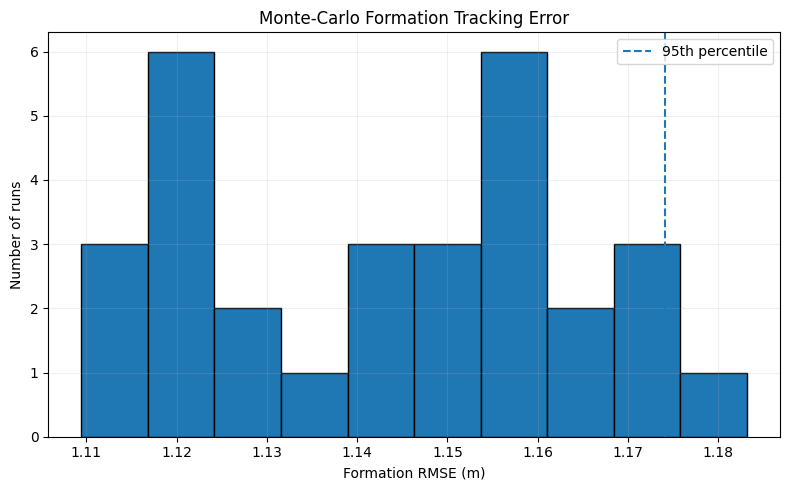

Saved digital_twin_mc_results.csv


In [9]:

MC=30; results=[]
for s in range(MC):
    h=simulate("advanced",1000+s,loss_scale=np.random.default_rng(5000+s).uniform(.6,2.8),sensor_sigma=np.random.default_rng(6000+s).uniform(.015,.07))
    results.append([np.sqrt(np.mean(h["formation_rms"]**2)),np.max(h["formation_rms"]),np.min(h["min_distance"]),np.mean(h["packet_drop"])*100,np.mean(h["control_effort"])])
results=np.array(results)
print("="*70); print(f"MONTE-CARLO RELIABILITY STUDY: {MC} RUNS"); print("="*70)
print(f"Mean RMSE: {results[:,0].mean():.4f} m"); print(f"95th percentile RMSE: {np.percentile(results[:,0],95):.4f} m"); print(f"Worst peak error: {results[:,1].max():.4f} m"); print(f"Worst minimum separation: {results[:,2].min():.4f} m"); print(f"Mean packet loss: {results[:,3].mean():.2f}%"); print(f"Mean control effort: {results[:,4].mean():.4f}")
plt.figure(figsize=(8,5)); plt.hist(results[:,0],bins=10,edgecolor="black"); plt.axvline(np.percentile(results[:,0],95),linestyle="--",label="95th percentile"); plt.xlabel("Formation RMSE (m)"); plt.ylabel("Number of runs"); plt.title("Monte-Carlo Formation Tracking Error"); plt.grid(True,alpha=.2); plt.legend(); plt.tight_layout(); plt.show()
np.savetxt("digital_twin_mc_results.csv",results,delimiter=",",header="RMSE,PeakError,MinSeparation,PacketLoss,ControlEffort",comments="")
print("Saved digital_twin_mc_results.csv")


In [10]:

# Optional animation. In Colab/Jupyter this renders an interactive HTML animation.
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
fig,ax=plt.subplots(figsize=(8,6))
colors=plt.cm.viridis(np.linspace(0,1,N_AGENTS))
def update(frame):
    ax.clear(); k=min(frame*4,N-1)
    for i in range(N_AGENTS):
        tr=hist_adv["states"][:k+1,i]; ax.plot(tr[:,0],tr[:,1],color=colors[i],linewidth=1.3); ax.scatter(tr[-1,0],tr[-1,1],color=colors[i],s=80); ax.text(tr[-1,0]+.08,tr[-1,1]+.08,f"A{i}")
    ax.set_xlim(*WORLD_LIMITS[:2]); ax.set_ylim(*WORLD_LIMITS[2:]); ax.set_aspect("equal"); ax.grid(True,alpha=.25); ax.set_title(f"Multi-Agent Digital Twin | t={T[k]:.2f}s"); ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")
anim=FuncAnimation(fig,update,frames=N//4,interval=40); plt.close(fig); HTML(anim.to_jshtml())
